In [64]:
import pandas as pd
import matplotlib.pyplot as plt

In [66]:
df = pd.read_csv("OnlineRetail.csv", encoding='ISO-8859-1')  

In [67]:
df.shape

(541909, 8)

In [70]:
df.columns.tolist()

['InvoiceNo',
 'StockCode',
 'Description',
 'Quantity',
 'InvoiceDate',
 'UnitPrice',
 'CustomerID',
 'Country']

In [72]:
df.dtypes

InvoiceNo       object
StockCode       object
Description     object
Quantity         int64
InvoiceDate     object
UnitPrice      float64
CustomerID     float64
Country         object
dtype: object

In [74]:
df.head(5)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [76]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


In [78]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [80]:
df.describe()

,Quantity,UnitPrice,CustomerID
count,541909.000000,541909.000000,406829.000000
mean,9.552250,4.611114,15287.690570
std,218.081158,96.759853,1713.600303
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13953.000000
50%,3.000000,2.080000,15152.000000
75%,10.000000,4.130000,16791.000000
max,80995.000000,38970.000000,18287.000000


In [82]:
df.duplicated().sum()

5268

In [84]:
df["Country"].unique()

array(['United Kingdom', 'France', 'Australia', 'Netherlands', 'Germany',
       'Norway', 'EIRE', 'Switzerland', 'Spain', 'Poland', 'Portugal',
       'Italy', 'Belgium', 'Lithuania', 'Japan', 'Iceland',
       'Channel Islands', 'Denmark', 'Cyprus', 'Sweden', 'Austria',
       'Israel', 'Finland', 'Bahrain', 'Greece', 'Hong Kong', 'Singapore',
       'Lebanon', 'United Arab Emirates', 'Saudi Arabia',
       'Czech Republic', 'Canada', 'Unspecified', 'Brazil', 'USA',
       'European Community', 'Malta', 'RSA'], dtype=object)

In [86]:
not_uk = df[df['Country'] != 'United Kingdom']
country_count = not_uk['Country'].value_counts()
top5 = country_count.head(5)
print(top5)

Country
Germany        9495
France         8557
EIRE           8196
Spain          2533
Netherlands    2371
Name: count, dtype: int64


In [88]:
product_qty = df.groupby('Description')['Quantity'].sum()
top5_products = product_qty.sort_values(ascending=False).head(5)
print(top5_products)

Description
WORLD WAR 2 GLIDERS ASSTD DESIGNS    53847
JUMBO BAG RED RETROSPOT              47363
ASSORTED COLOUR BIRD ORNAMENT        36381
POPCORN HOLDER                       36334
PACK OF 72 RETROSPOT CAKE CASES      36039
Name: Quantity, dtype: int64


In [90]:
df['Revenue'] = df['Quantity'] * df['UnitPrice']
country_total = df.groupby('Country')['Revenue'].sum()
country_total_sorted = country_total.sort_values(ascending=False)
print(country_total_sorted)

Country
United Kingdom          8187806.364
Netherlands              284661.540
EIRE                     263276.820
Germany                  221698.210
France                   197403.900
Australia                137077.270
Switzerland               56385.350
Spain                     54774.580
Belgium                   40910.960
Sweden                    36595.910
Japan                     35340.620
Norway                    35163.460
Portugal                  29367.020
Finland                   22326.740
Channel Islands           20086.290
Denmark                   18768.140
Italy                     16890.510
Cyprus                    12946.290
Austria                   10154.320
Hong Kong                 10117.040
Singapore                  9120.390
Israel                     7907.820
Poland                     7213.140
Unspecified                4749.790
Greece                     4710.520
Iceland                    4310.000
Canada                     3666.380
Malta               

In [92]:
customer_qty = df.groupby('CustomerID')['Quantity'].sum()
top5_customers = customer_qty.sort_values(ascending=False).head(5)
print(top5_customers)

CustomerID
14646.0    196719
12415.0     77242
14911.0     77180
17450.0     69029
18102.0     64122
Name: Quantity, dtype: int64


In [94]:
avg_price = df['UnitPrice'].mean()
print("Average Price:", avg_price)

Average Price: 4.611113626088513


In [96]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
df['Date'] = df['InvoiceDate'].dt.date
daily_total = df.groupby('Date')['Revenue'].sum()
top_day = daily_total.sort_values(ascending=False).head(1)
print(top_day)

Date
2011-11-14    112141.11
Name: Revenue, dtype: float64


In [98]:
items_per_bill = df.groupby('InvoiceNo')['Quantity'].sum()
avg_items = items_per_bill.mean()
print("Average Items per Invoice:", avg_items)

Average Items per Invoice: 199.86293436293437


In [100]:
common_prices = df['UnitPrice'].value_counts()
top5_prices = common_prices.head(5)
print(top5_prices)

UnitPrice
1.25    50496
1.65    38181
0.85    28497
2.95    27768
0.42    24533
Name: count, dtype: int64


In [102]:
returned = df[df['Quantity'] < 0]
returned_products = returned['Description'].nunique()
print("Returned Products:", returned_products)

Returned Products: 2110


In [104]:
product_revenue = df.groupby('Description')['Revenue'].sum()
top5_revenue = product_revenue.sort_values(ascending=False).head(5)
print(top5_revenue)

Description
DOTCOM POSTAGE                        206245.48
REGENCY CAKESTAND 3 TIER              164762.19
WHITE HANGING HEART T-LIGHT HOLDER     99668.47
PARTY BUNTING                          98302.98
JUMBO BAG RED RETROSPOT                92356.03
Name: Revenue, dtype: float64


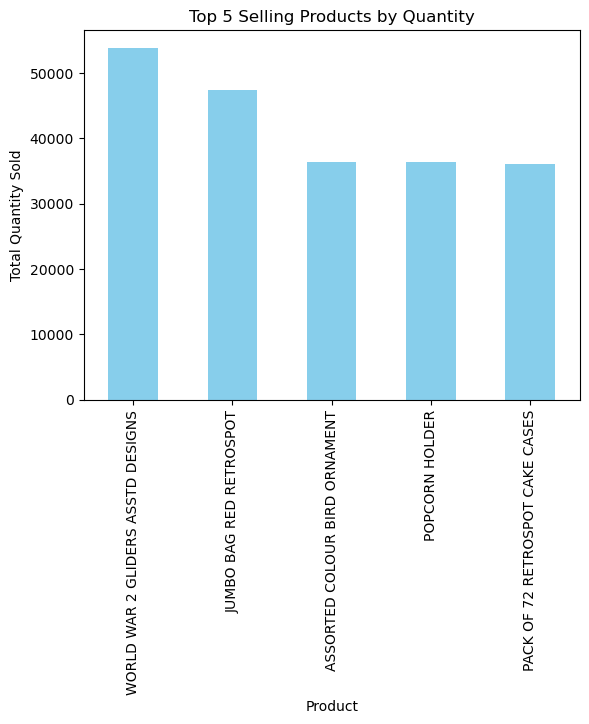

In [106]:
top5_products = df.groupby('Description')['Quantity'].sum().sort_values(ascending=False).head(5)

top5_products.plot(kind='bar', color='skyblue')
plt.title('Top 5 Selling Products by Quantity')
plt.ylabel('Total Quantity Sold')
plt.xlabel('Product')
plt.show()

Text(0.5, 1.0, 'Top 5 Countries by Revenue')

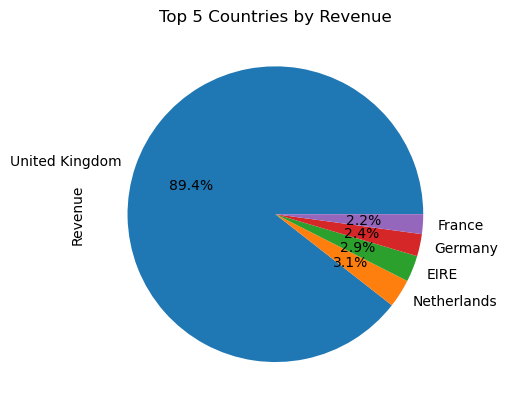

In [108]:
top5_countries = df.groupby('Country')['Revenue'].sum().sort_values(ascending = False).head(5)
top5_countries.plot(kind='pie', autopct='%1.1f%%')
plt.title('Top 5 Countries by Revenue')


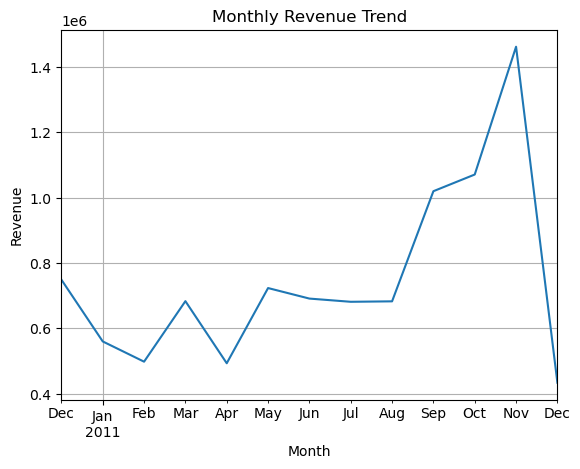

In [110]:
monthly_revenue = df.set_index('InvoiceDate').resample('ME')['Revenue'].sum()

monthly_revenue.plot()
plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.grid(True)
plt.show()

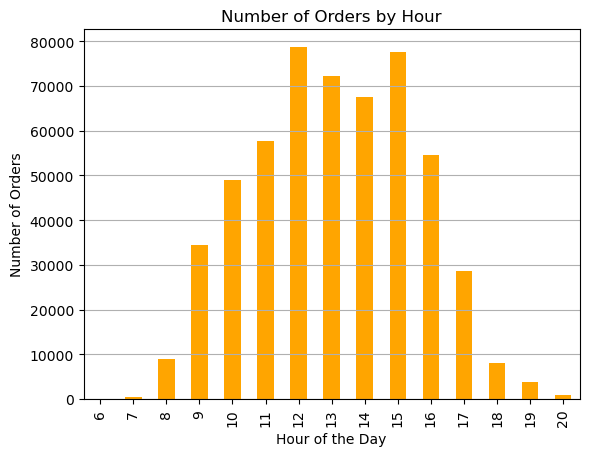

In [112]:
df['Hour'] = df['InvoiceDate'].dt.hour
orders_by_hour = df['Hour'].value_counts().sort_index()
orders_by_hour.plot(kind='bar', color='orange')
plt.title('Number of Orders by Hour')
plt.xlabel('Hour of the Day')
plt.ylabel('Number of Orders')
plt.grid(axis='y')
plt.show()

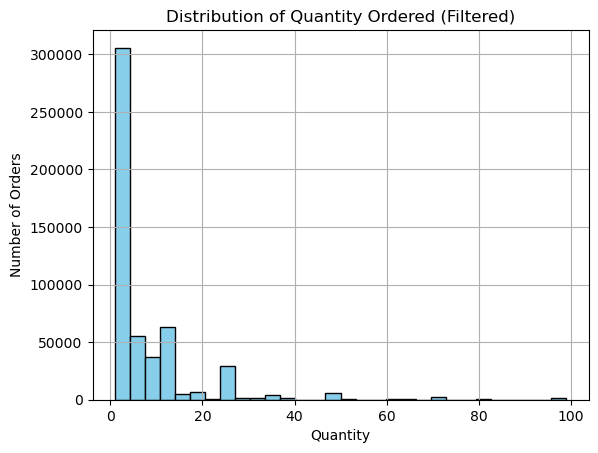

In [114]:
#Remove negative quantities and very large ones and outliers
df_clean = df[(df['Quantity'] > 0) & (df['Quantity'] < 100)]

plt.hist(df_clean['Quantity'], bins=30, color='skyblue', edgecolor='black')
plt.title('Distribution of Quantity Ordered (Filtered)')
plt.xlabel('Quantity')
plt.ylabel('Number of Orders')
plt.grid(True)
plt.show()